# Decision Trees Exercises

![DecisionTree.png](Assets/DecisionTree.png)


# Цели обучения

- Распознайте деревья решений и как их использовать для проблем классификации
- Узнайте, как определить наилучшее разделение и факторы для разделения
- Объясните сильные и слабые стороны деревьев для принятия решений
- Объясните, как деревья регрессии помогают классифицировать непрерывные значения
- Примените расширение Intel® для Scikit-learn*, чтобы использовать базовые вычислительные возможности оборудования




## Введение

Мы будем использовать набор данных качества вина для этих упражнений. Этот набор данных содержит различные химические свойства вина, такие как кислотность, сахар, pH и алкоголь. Он также содержит метрику качества (3-9, где самый высокий - лучше) и цвет (красный или белый). Имя файла - «Wine_Quality_Data.csv».

In [47]:
from __future__ import print_function
import os
data_path = ['data']

from io import StringIO
from IPython.display import Image, display

from sklearn.tree import export_graphviz
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import mean_squared_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier

from sklearnex import patch_sklearn
patch_sklearn()

Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Вопрос 1

* Импортируйте данные и изучите функции.
* Мы будем использовать их все для прогнозирования `color` (белого или красного), но функция цветов должна быть закодирована на целое число.

Преобразуйте цветовую функцию в целое число. Это быстрый способ сделать это с помощью  Pandas.

In [48]:
# Импорт библиотек
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [49]:
# Импортируйте данные и изучите признаки
filepath = os.sep.join(data_path + ['Wine_Quality_Data.csv'])
data = pd.read_csv(filepath, sep=',')
data.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [50]:
# Типы данных каждого признака
data.dtypes

fixed_acidity           float64
volatile_acidity        float64
citric_acid             float64
residual_sugar          float64
chlorides               float64
free_sulfur_dioxide     float64
total_sulfur_dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
color                    object
dtype: object

In [51]:
# Преобразуйте признак color в целое число: white -> 0, red -> 1
data['color'] = data['color'].map({'white': 0, 'red': 1}).astype(int)
data.dtypes

fixed_acidity           float64
volatile_acidity        float64
citric_acid             float64
residual_sugar          float64
chlorides               float64
free_sulfur_dioxide     float64
total_sulfur_dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
color                     int64
dtype: object

## Вопрос 2

* Используйте `StratifiedShuffleSplit` для разделения данных на наборы поездов и тестов, которые стратифицированы по качеству вина. Если возможно, сохраните индексы доли для вопроса 5 ниже.
* Проверьте процентный состав каждого уровня качества для наборов данных о поезде и тестовых данных.

Теперь проверьте процентную долю каждого уровня качества в обучающем и тестовом наборах данных. Как видно ниже, набор данных в основном состоит из белого вина.

In [52]:
# Признаки — все столбцы, кроме color
feature_cols = [x for x in data.columns if x != 'color']

# Используйте StratifiedShuffleSplit для разделения данных на train и test,
# стратифицированных по качеству вина
strat_shuf_split = StratifiedShuffleSplit(n_splits=1, test_size=1000, random_state=42)

# Сохраните индексы разбиения для вопроса 5
train_idx, test_idx = next(strat_shuf_split.split(data[feature_cols], data['quality']))

# Обучающий набор
X_train = data.loc[train_idx, feature_cols]
y_train = data.loc[train_idx, 'color']

# Тестовый набор
X_test = data.loc[test_idx, feature_cols]
y_test = data.loc[test_idx, 'color']

In [53]:
# Проверьте процентный состав каждого уровня качества в train и test
pd.concat([X_train['quality'].value_counts(normalize=True).sort_index(),
           X_test['quality'].value_counts(normalize=True).sort_index()],
          axis=1, keys=['train', 'test'])

,train,test
quality,,
3,0.004548,0.005
4,0.033291,0.033
5,0.329089,0.329
6,0.436602,0.436
7,0.166091,0.166
8,0.029653,0.030
9,0.000728,0.001


In [54]:
# Процентная доля цвета вина (0 — белое, 1 — красное) в train и test
pd.concat([y_train.value_counts(normalize=True).sort_index(),
           y_test.value_counts(normalize=True).sort_index()],
          axis=1, keys=['train', 'test'])

,train,test
color,,
0,0.75332,0.757
1,0.24668,0.243


## Вопрос 3

* Постройте классификатор на основе дерева решений без ограничений на максимальную глубину, количество признаков или количество листьев.
* Определите, сколько узлов присутствует в этом (очень большом) дереве и какова его глубина.
* Используя это дерево, оцените погрешность прогнозирования на обучающем и тестовом наборах данных. Как вы думаете, что здесь происходит, исходя из различий в погрешности прогнозирования?

Количество узлов и максимальная фактическая глубина.

Дерево решений демонстрирует чуть более точные прогнозы на обучающих данных, чем на тестовых, что свидетельствует о (незначительной) переобученности. Также обратите внимание на идеальный показатель воспроизводимости для обучающих данных. Во многих случаях разница в точности прогнозов бывает даже больше, чем показано здесь.

In [55]:
# Постройте дерево решений без ограничений на глубину, число признаков и число листьев
dt = DecisionTreeClassifier(random_state=42)
dt = dt.fit(X_train, y_train)

In [56]:
# Определите количество узлов и глубину дерева
dt.tree_.node_count, dt.tree_.max_depth

(165, 21)

In [57]:
# Функция для расчёта погрешности прогнозирования
def measure_error(y_true, y_pred, label):
    return pd.Series({'accuracy': accuracy_score(y_true, y_pred),
                      'precision': precision_score(y_true, y_pred),
                      'recall': recall_score(y_true, y_pred),
                      'f1': f1_score(y_true, y_pred)},
                     name=label)

In [58]:
# Прогнозы на обучающем и тестовом наборах
y_train_pred = dt.predict(X_train)
y_test_pred = dt.predict(X_test)

# Оцените погрешность на train и test
train_test_full_error = pd.concat([measure_error(y_train, y_train_pred, 'train'),
                                   measure_error(y_test, y_test_pred, 'test')],
                                  axis=1)
train_test_full_error

,train,test
accuracy,0.999636,0.977000
precision,0.999263,0.929688
recall,0.999263,0.979424
f1,0.999263,0.953908


## Вопрос 4

* С помощью сетчатого поиска с перекрестной валидацией найдите дерево решений, которое демонстрирует хорошие результаты на тестовом наборе данных. Присвойте этой модели дерева решений другое имя переменной, чем в вопросе 3, чтобы обе модели можно было использовать в вопросе 6.
* Определите количество узлов и глубину этого дерева.
* Рассчитайте погрешности на обучающем и тестовом наборах данных, как и ранее, и сравните их с погрешностями дерева из вопроса 3.

Количество узлов и максимальная глубина дерева.

Эти ошибки тестирования немного лучше, чем предыдущие. Таким образом, можно сделать вывод, что в предыдущем примере имело место переобучение, но лишь в незначительной степени.

In [59]:
# Сетка параметров: глубина дерева и количество признаков
param_grid = {'max_depth': range(1, dt.tree_.max_depth + 1, 2),
              'max_features': range(1, len(dt.feature_importances_) + 1)}

# Сетчатый поиск с перекрестной валидацией
GR = GridSearchCV(DecisionTreeClassifier(random_state=42),
                  param_grid=param_grid,
                  scoring='accuracy',
                  n_jobs=-1)

GR = GR.fit(X_train, y_train)

In [60]:
# Лучшая модель — под другим именем, чем dt из вопроса 3
dt_gr = GR.best_estimator_
GR.best_params_

{'max_depth': 9, 'max_features': 8}

In [61]:
# Определите количество узлов и глубину этого дерева
dt_gr.tree_.node_count, dt_gr.tree_.max_depth

(109, 9)

In [62]:
# Прогнозы лучшей модели на train и test
y_train_pred_gr = dt_gr.predict(X_train)
y_test_pred_gr = dt_gr.predict(X_test)

# Погрешности на train и test
train_test_gr_error = pd.concat([measure_error(y_train, y_train_pred_gr, 'train'),
                                 measure_error(y_test, y_test_pred_gr, 'test')],
                                axis=1)
train_test_gr_error

,train,test
accuracy,0.995998,0.978000
precision,0.999251,0.940239
recall,0.984513,0.971193
f1,0.991828,0.955466


In [63]:
# Сравните с погрешностями дерева из вопроса 3
pd.concat([train_test_full_error, train_test_gr_error],
          axis=1, keys=['Вопрос 3 (без ограничений)', 'Вопрос 4 (GridSearchCV)'])

Вопрос 3 (без ограничений)           Вопрос 4 (GridSearchCV)  \
                               train      test                   train   
accuracy                    0.999636  0.977000                0.995998   
precision                   0.999263  0.929688                0.999251   
recall                      0.999263  0.979424                0.984513   
f1                          0.999263  0.953908                0.991828   

                     
               test  
accuracy   0.978000  
precision  0.940239  
recall     0.971193  
f1         0.955466

## Вопрос 5

* Снова разделите данные на части `X` и `y`, на этот раз с `residual_sugar` в качестве прогнозируемых (`y`) данных. *Примечание:* если индексы были сохранены из результатов `StratifiedShuffleSplit` в вопросе 2, их можно использовать повторно для разделения данных.
* Используя поиск по сетке с перекрестной валидацией, найдите модель **регрессии** на основе дерева решений, которая хорошо работает на тестовом наборе данных.
* Оцените погрешности на обучающем и тестовом наборах данных с помощью среднеквадратичной ошибки.
* Постройте график, на котором будут отображены фактические *и* прогнозируемые значения остаточного сахара.

Количество узлов и максимальная глубина дерева. В этом дереве много узлов, что неудивительно, учитывая непрерывный характер данных.

Ошибка на обучающем и тестовом наборах данных. Поскольку речь идет о непрерывных величинах, мы будем использовать среднеквадратичную ошибку.

График, отражающий соотношение фактического и прогнозируемого остаточного содержания сахара.

In [64]:
# Снова разделите данные на X и y, теперь y — residual_sugar
feature_cols = [x for x in data.columns if x != 'residual_sugar']

# Используем индексы train_idx и test_idx, сохранённые в вопросе 2
X_train = data.loc[train_idx, feature_cols]
y_train = data.loc[train_idx, 'residual_sugar']

X_test = data.loc[test_idx, feature_cols]
y_test = data.loc[test_idx, 'residual_sugar']

In [65]:
# Поиск по сетке с перекрестной валидацией для модели регрессии на основе дерева решений
param_grid = {'max_depth': range(1, dt.tree_.max_depth + 1, 2),
              'max_features': range(1, len(feature_cols) + 1)}

GR_sugar = GridSearchCV(DecisionTreeRegressor(random_state=42),
                        param_grid=param_grid,
                        scoring='neg_mean_squared_error',
                        n_jobs=-1)

GR_sugar = GR_sugar.fit(X_train, y_train)
GR_sugar.best_params_

{'max_depth': 21, 'max_features': 12}

In [66]:
# Количество узлов и максимальная глубина дерева
dt_sugar = GR_sugar.best_estimator_
dt_sugar.tree_.node_count, dt_sugar.tree_.max_depth

(7677, 21)

In [67]:
# Оцените погрешности на train и test с помощью среднеквадратичной ошибки
y_train_pred_sugar = dt_sugar.predict(X_train)
y_test_pred_sugar = dt_sugar.predict(X_test)

train_test_sugar_error = pd.Series({'train': mean_squared_error(y_train, y_train_pred_sugar),
                                    'test': mean_squared_error(y_test, y_test_pred_sugar)},
                                   name='MSE').to_frame().T
train_test_sugar_error

,train,test
MSE,0.001729,3.304784


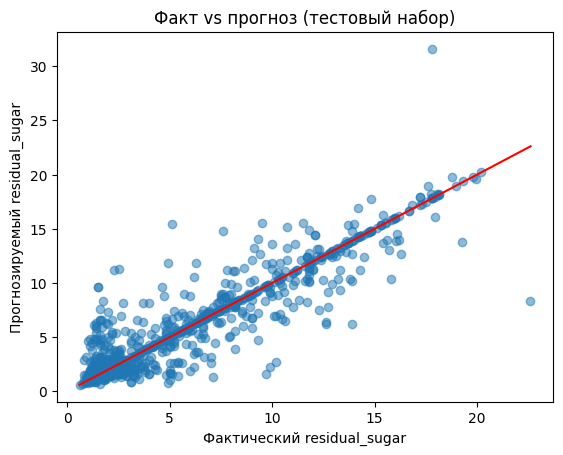

In [68]:
# График фактических и прогнозируемых значений остаточного сахара
ax = plt.axes()
ax.scatter(y_test, y_test_pred_sugar, alpha=0.5)

# Линия идеального прогноза: прогноз = факт
lims = [y_test.min(), y_test.max()]
ax.plot(lims, lims, color='red')

ax.set(xlabel='Фактический residual_sugar',
       ylabel='Прогнозируемый residual_sugar',
       title='Факт vs прогноз (тестовый набор)')
plt.show()

## Вопрос 6 *(Необязательный)*

Этот вопрос является необязательным, так как для его решения требуется дополнительная программа командной строки (GraphViz) и библиотека Python (PyDotPlus). GraphViz можно установить с помощью менеджера пакетов в Linux и Mac. Для установки библиотеки PyDotPlus можно использовать либо `pip`, либо `conda` (`conda install -c conda-forge pydotplus`).

После установки этих программ:

* Создайте визуализацию дерева решений из вопроса 3, в котором предсказывался цвет вина, а количество признаков и/или разбиений не ограничено.
* Создайте визуализацию дерева решений из вопроса 4, в котором предсказывался цвет вина, но для нахождения оптимальной глубины и количества признаков использовался поиск по сетке.

Дерево решений из вопроса 5, скорее всего, будет иметь слишком много узлов для визуализации.

In [69]:
try:
    import pydotplus
    pydotplus_installed = True
    
except:
    print('PyDotPlus must be installed to execute the remainder of the cells associated with this question.')
    print('Please see the instructions for this question for details.')
    pydotplus_installed = False

PyDotPlus must be installed to execute the remainder of the cells associated with this question.
Please see the instructions for this question for details.


Дерево из вопроса 3.

Дерево, построенное с помощью перекрестной валидации из вопроса 4. Это дерево намного менее глубокое, чем предыдущее.